In [1]:
!pip install /kaggle/input/datasets/malihealavi/monai-1-4-0/monai-1.4.0-py3-none-any.whl \
    --no-deps \
    --force-reinstall
import monai
print(monai.__version__)  # Should show 1.4.0

Processing /kaggle/input/datasets/malihealavi/monai-1-4-0/monai-1.4.0-py3-none-any.whl


2026-06-27 13:53:09.020824: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782568389.236137      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782568389.299655      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782568389.814509      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782568389.814556      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782568389.814559      23 computation_placer.cc:177] computation placer alr

1.4.0


In [2]:

import warnings
warnings.filterwarnings("ignore")
import os
import sys 
import json
from glob import glob
import random
import collections
import time
import re
import monai.transforms as mt
from typing import Optional

import numpy as np
import pandas as pd
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

import torch
from torch import nn
from torch.utils import data as torch_data
from sklearn import model_selection as sk_model_selection
from torch.nn import functional as torch_functional
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from IPython.display import clear_output
clear_output()


In [3]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    # Warning: the following lines can slow down training performance slightly
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()


In [4]:
TRAIN_DIR = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train'
TEST_DIR = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/test'
data_directory = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification'
train_scan_ids = [f for f in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, f))]
train_scan_ids.sort()
test_scan_ids = [f for f in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, f))]
test_scan_ids.sort()
NUM_SLICES = 32
IMAGE_SIZE = 256

In [5]:
train_df = pd.read_csv(cfg.paths.train_root)
train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
values_to_drop = ['00109', '00123', '00709']
df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)]
T1wCE_dict, t1w_dict, t2w_dict, flair_dict = {},{},{},{}
for scan_id in train_df['BraTS21ID']:
    break
    path_pattern = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train/{scan_id}/T1w/*.dcm"
    files = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    t1w_dict.update({scan_id : len(files) })
    
    path_pattern1 = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train/{scan_id}/FLAIR/*.dcm"
    files1 = sorted(glob(path_pattern1), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    flair_dict.update({scan_id : len(files1) })
    
    path_pattern2 = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train/{scan_id}/T2w/*.dcm"
    files2 = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    t2w_dict.update({scan_id : len(files2) })
    
    path_pattern3 = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train/{scan_id}/T1wCE/*.dcm"
    files3 = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    T1wCE_dict.update({scan_id : len(files3) })
    # break




In [6]:
# from collections import Counter

# print(min(flair_dict.values()) , max(flair_dict.values()), )
# print(min(t1w_dict.values()) , max(t1w_dict.values()) ,  )
# print(min(t2w_dict.values()) , max(t2w_dict.values()),)
# print(min(T1wCE_dict.values()) , max(T1wCE_dict.values()),)



In [7]:


def load_dicom_image(path, img_size, voi_lut=True, rotate=0):
    dicom = pydicom.dcmread(path)
    if voi_lut:
        try:
            data = apply_voi_lut(dicom.pixel_array, dicom)
        except Exception:
            data = dicom.pixel_array
    else:
        data = dicom.pixel_array
        
    data = data.astype(np.float32)
          
    # # # Resize to the standard bounding dimensions
    # data = cv2.resize(data, (img_size, img_size))
    return data


def load_dicom_images_3d(scan_id, num_imgs, img_size, mri_type="FLAIR", split="train", rotate=0, data_directory="."):
    path_pattern = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/{split}/{scan_id}/{mri_type}/*.dcm"
    files = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    
    if len(files) == 0:
        print(scan_id,':',mri_type)
        return np.zeros(( num_imgs, img_size, img_size), dtype=np.float32)
    
    middle = len(files) // 2
    num_imgs2 = num_imgs // 2
    # plt.imshow(load_dicom_image(files[middle], img_size=256, rotate=0) , cmap='gray')   
    p1 = max(0, middle - num_imgs2)
    p2 = min(len(files), middle + num_imgs2)
    
    img3d = np.stack([load_dicom_image(f, img_size=img_size, rotate=rotate, voi_lut=True) for f in files[p1:p2]], axis=0) 
    # ----------- img3d = num_slices * H*W
    # return img3d  
    return img3d



(32, 256, 256) 20500.484 -32768.0


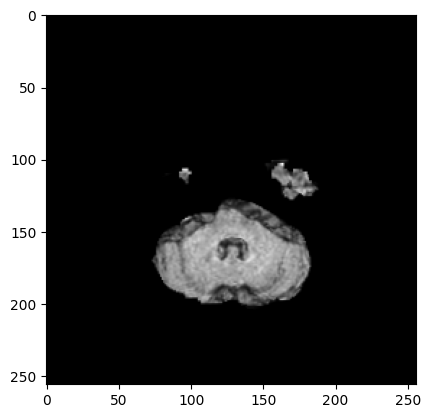

In [8]:
sample1 = load_dicom_images_3d('00143', 32, 256, mri_type="FLAIR", split="train", rotate=0, )
print(sample1.shape, np.max(sample1) , np.min(sample1))
plt.imshow(sample1[12], cmap='gray')


(32, 256, 256) 20500.484 -32768.0


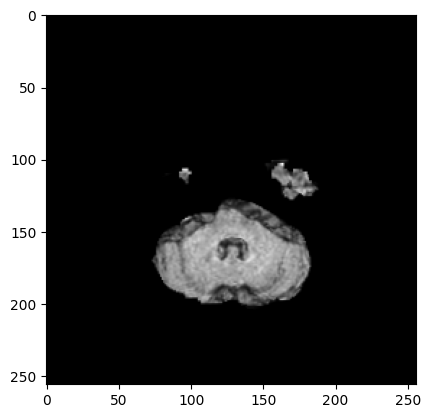

In [9]:
sample1 = load_dicom_images_3d('00143', 32, 256, mri_type="FLAIR", split="train", rotate=0, )
print(sample1.shape, np.max(sample1) , np.min(sample1))
plt.imshow(sample1[12], cmap='gray')


# Dataset , Augment

In [ ]:
from typing import List
# Define the exact keys your dataset dictionary outputs
mri_keys = ["FLAIR", "T1w", "T1wCE", "T2w"]

def get_train_transform(num_slices: int, image_size: int, mri_keys: List[str] = ["FLAIR", "T1w", "T1wCE", "T2w"]) -> mt.Compose:
    return mt.Compose([
        mt.EnsureChannelFirstd(keys=mri_keys, channel_dim="no_channel"),
        mt.Resized(keys=mri_keys, spatial_size=(num_slices, image_size, image_size), mode="trilinear"),
        
        mt.NormalizeIntensityd(keys=mri_keys, nonzero=True, channel_wise=True),
        
        mt.RandFlipd(keys=mri_keys, prob=0.5, spatial_axis=2),   # L/R flip 
        mt.RandFlipd(keys=mri_keys, prob=0.5, spatial_axis=1),   # A/P flip 
        mt.RandRotated(
            keys=mri_keys,
            range_x=0.2, range_y=0.2, range_z=0.2,   # ~±11° max
            prob=0.5, mode="bilinear", padding_mode="zeros"
        ),
        mt.RandZoomd(keys=mri_keys, min_zoom=0.9, max_zoom=1.1, prob=0.3),
        
        # MRI-specific intensity augmentations
        mt.RandGaussianNoised(keys=mri_keys, prob=0.3, mean=0.0, std=0.05),
        mt.RandShiftIntensityd(keys=mri_keys, offsets=0.1, prob=0.4),
        mt.RandScaleIntensityd(keys=mri_keys, factors=0.15, prob=0.4),
        mt.RandBiasFieldd(keys=mri_keys, prob=0.3, coeff_range=(0.0, 0.3)),
        mt.RandGibbsNoised(keys=mri_keys, prob=0.15, alpha=(0.0, 0.4)),
    ])
def get_val_transform(num_slices: int, image_size: int, mri_keys: List[str] = ["FLAIR", "T1w", "T1wCE", "T2w"]) -> mt.Compose:
   
    return mt.Compose([
        mt.EnsureChannelFirstd(keys=mri_keys, channel_dim="no_channel"),
        mt.Resized(keys=mri_keys, spatial_size=(num_slices, image_size, image_size), mode="trilinear"),
        mt.NormalizeIntensityd(keys=mri_keys, nonzero=True, channel_wise=True),  # ← ADD THIS
    ])
    
val_transform_func = get_val_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)
train_transform_func = get_train_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)

In [11]:
class Dataset(Dataset):
    def __init__(self, df, scan_ids, split , img_size = IMAGE_SIZE, num_images= NUM_SLICES ,augmentation=None):
        self.scan_ids = scan_ids
        self.augmentation = augmentation
        self.num_images = num_images
        self.img_size = img_size  
        self.split = split  
        self.train_labels = df
        self.mri_type = ['FLAIR' , 'T1w' , 'T1wCE', 'T2w']
    def __len__(self):
        return len(self.scan_ids)
 
    def __getitem__(self, idx):
        
        flair_3d = load_dicom_images_3d(scan_id =  self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="FLAIR", split= self.split)
        t1w_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T1w", split= self.split)
        t1wce_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T1wCE", split = self.split)
        t2w_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T2w", split = self.split)
       
        if self.augmentation:
            data_dict = {
                "FLAIR": flair_3d,
                "T1w": t1w_3d,
                "T1wCE": t1wce_3d,
                "T2w": t2w_3d
            }
            # MONAI applies the identical random matrix transform to all dictionary keys
            augmented = self.augmentation(data_dict)
            
            # Squeeze out the channel dimension added by EnsureChannelFirstd
            flair_3d = augmented["FLAIR"].squeeze(0)
            t1wce_3d = augmented["T1wCE"].squeeze(0)
            t2w_3d = augmented["T2w"].squeeze(0)
            t1w_3d = augmented["T1w"].squeeze(0)
            
        else:
            # Convert to torch tensors if no augmentation is run
            flair_3d = torch.as_tensor(flair_3d, dtype=torch.float32)
            t1w_3d = torch.as_tensor(t1w_3d, dtype=torch.float32)
            t1wce_3d = torch.as_tensor(t1wce_3d, dtype=torch.float32)
            t2w_3d = torch.as_tensor(t2w_3d, dtype=torch.float32)
        # print(f'shape is :{t2w_3d.shape}')
            
        if self.split == 'train':
            target = self.train_labels['MGMT_value'].iloc[idx]
            return torch.stack([flair_3d ,t1w_3d, t1wce_3d, t2w_3d ], dim=0) , target
        else:
            return torch.stack([flair_3d ,t1w_3d, t1wce_3d, t2w_3d ], dim=0) 
            
        

In [12]:
def plot_loss(val_losses, train_losses,val_auc  ,path):
    epochs = range(1, len(train_losses) + 1)
    
    # Plot both training and validation losses
    plt.plot(epochs, train_losses, label='Training Loss', color='blue', marker='o', linewidth=2)
    plt.plot(epochs, val_losses, label='Validation Loss', color='red', marker='o', linewidth=2)
    plt.plot(epochs, val_auc, label='Validation AUC', color='green', marker='o', linewidth=2)
    
    # Styling the plot
    plt.title('Training and Validation Loss Over Epochs', fontsize=14)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    
    # Ensure x-axis only shows integer values for epochs
    plt.xticks(epochs)
    
    # Add a legend to differentiate the lines
    plt.legend(fontsize=11)
    
    # Add a grid for better readability
    plt.grid(True, linestyle='--', alpha=0.6)
    plot_path = path
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    # 4. Clean up the memory (highly recommended for background runs)
    plt.close()
    
    print(f"Plot successfully saved to {os.path.abspath(plot_path)}")


# Model

In [13]:
from monai.networks.nets import resnet10 ,resnet18, EfficientNetBN

class Model_3D(nn.Module):
    def __init__(self, pretrained=True , bb='resnet10'):
        super(Model_3D, self).__init__()
        
        if bb == 'resnet10':
            self.backbone = resnet10(
                spatial_dims=3,          # Explicitly set to 3D convolutions
                n_input_channels=4,      # FLAIR, T1w, T1wCE, T2w 
                num_classes=1            # Single logit output for Binary Classification
            )
            
        elif bb == 'resnet18':
            self.backbone = resnet18(
                spatial_dims=3,          # Explicitly set to 3D convolutions
                n_input_channels=4,      # FLAIR, T1w, T1wCE, T2w 
                num_classes=1            # Single logit output for Binary Classification
            )
            
        elif bb == 'efficientnet':
            self.backbone = EfficientNetBN(
                model_name="efficientnet-b0",
                spatial_dims=3,          # Explicitly set to 3D convolutions
                in_channels=4,           # 4 distinct channels: FLAIR, T1w, T1wCE, T2w
                num_classes=1,           # Single logit output for Binary Classification
                pretrained=False         # Note: 3D pretrained weights are rare, usually set to False unless using a specific medical checkpoint
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.backbone(x)
        return logits


# Trainer

In [14]:

class Trainer():
    def __init__(self, 
                 train_df : pd.DataFrame, 
                 epochs:int, 
                 device:str, 
                 train_transform_func:mt.Compose,
                 val_transform_func:mt.Compose,
                 scaler: Optional[torch.cuda.amp.GradScaler]=None):
        """
        Args:
            scan_id: list of all patients' ids in trainset , id type : str 
            epochs: Number of epochs
            device: cpu / gpu 
            scaler: Optional GradScaler for mixed precision.
        """
        self.train_transform = train_transform_func
        self.val_transform = val_transform_func
        self.model = Model_3D(bb='resnet18')
        self.model.to(device)
        self.epochs = epochs
        self.optimizer = optim.AdamW(self.model.parameters(), lr=5e-5, weight_decay=1e-2)
        self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.optimizer, T_max=epochs, eta_min=1e-6)
        self.device = device
        self.scaler = scaler
        self.accumulation_steps = 4 
        # ------------------- Loss & Eval ------------------
        train, val = train_test_split(train_df, test_size=0.2, stratify=train_df["MGMT_value"])
        pos_weights = (train['MGMT_value'] == 0).sum() / (train['MGMT_value'] == 1).sum()  
        pos_weight_tensor = torch.tensor([pos_weights], dtype=torch.float32).to(device)
        self.criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
        self.best_auc = 0.0
        # ------------------- Data Loader------------------
        train = train.reset_index(drop=True)
        val = val.reset_index(drop=True)
        train_ds = Dataset(train, scan_ids = train['BraTS21ID'], split='train',augmentation = self.train_transform)
        val_ds = Dataset(val, scan_ids = val['BraTS21ID'] , split='train', augmentation = self.val_transform)

        self.train_loader = DataLoader(
                                dataset=train_ds,
                                batch_size=2,
                                shuffle=True,
                                num_workers=4,          
                                pin_memory=True    
                            ) 
        
        self.valid_loader = DataLoader(
                                dataset=val_ds,
                                batch_size=4,         
                                shuffle=False,          
                                num_workers=4,          
                                pin_memory=True  
                            ) 

    def train_one_epoch(self, epoch):
        self.model.train()
        running_loss = 0.0
        # tqdm for a clean progress bar
        progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.epochs} [Train]")

        for inputs, targets in progress_bar:
            # Move data to GPU
            inputs = inputs.to(self.device, dtype=torch.float32)
            targets = targets.to(self.device, dtype=torch.float32)

            self.optimizer.zero_grad()

            if self.scaler is not None:
                with torch.cuda.amp.autocast():
                    outputs = self.model(inputs).squeeze(-1) 
                    loss = self.criterion(outputs, targets)

                self.scaler.scale(loss).backward()
                self.scaler.step(self.optimizer)
                self.scaler.update()
            else:
                outputs = self.model(inputs).squeeze(-1)
                loss = self.criterion(outputs, targets)
                loss.backward()
                self.optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

        return running_loss / len(self.train_loader.dataset)

    def train_one_epoch_accumulation(self, epoch):
        self.model.train()
        running_loss = 0.0
        progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.epochs} [Train]")

        # 1. Clear gradients BEFORE the loop starts
        self.optimizer.zero_grad()

        for i, (inputs, targets) in enumerate(progress_bar):
            inputs = inputs.to(self.device, dtype=torch.float32)
            targets = targets.to(self.device, dtype=torch.float32)

            if self.scaler is not None:
                with torch.cuda.amp.autocast():
                    outputs = self.model(inputs).squeeze(-1) 
                    loss = self.criterion(outputs, targets)
                    
                    # 2. Normalize the loss to average the gradients
                    loss = loss / self.accumulation_steps

                # Accumulate gradients
                self.scaler.scale(loss).backward()
            else:
                outputs = self.model(inputs).squeeze(-1)
                loss = self.criterion(outputs, targets)
                
                # 2. Normalize the loss
                loss = loss / self.accumulation_steps
                
                # Accumulate gradients
                loss.backward()

            # 3. Step the optimizer ONLY every `accumulation_steps` 
            # (or if it is the very last batch of the epoch)
            if (i + 1) % self.accumulation_steps == 0 or (i + 1) == len(self.train_loader):
                if self.scaler is not None:
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                else:
                    self.optimizer.step()
                
                # Reset gradients for the next accumulation cycle
                self.optimizer.zero_grad()
            
            # Track the running loss (multiply back by accumulation_steps for accurate printing)
            running_loss += loss.item() * self.accumulation_steps * inputs.size(0)
            progress_bar.set_postfix({'loss': f"{loss.item() * self.accumulation_steps:.4f}"})

        return running_loss / len(self.train_loader.dataset)
    
    def valid_one_epoch(self, epoch):
        self.model.eval()
        running_loss = 0.0
        all_preds = []
        all_targets = []
        
        progress_bar = tqdm(self.valid_loader, desc=f"Epoch {epoch}/{self.epochs} [Valid]")

        with torch.no_grad():
            for inputs, targets in progress_bar:
                inputs = inputs.to(self.device, dtype=torch.float32)
                targets = targets.to(self.device, dtype=torch.float32)

                if self.scaler is not None:
                    with torch.cuda.amp.autocast():
                        outputs = self.model(inputs).squeeze(-1)
                        loss = self.criterion(outputs, targets)
                else:
                    outputs = self.model(inputs).squeeze(-1)
                    loss = self.criterion(outputs, targets)

                running_loss += loss.item() * inputs.size(0)

                # Convert raw logits into probabilities between 0 and 1 using Sigmoid [cite: 179]
                # We do not round to 0 or 1 because the metric needs intermediate thresholds [cite: 182, 189]
                preds = torch.sigmoid(outputs).cpu().numpy()
                all_preds.extend(preds)
                all_targets.extend(targets.cpu().numpy())

        epoch_loss = running_loss / len(self.valid_loader.dataset)
        # Calculate ROC-AUC to rank patients based on their estimated probability [cite: 187, 188]
        try:
            epoch_auc = roc_auc_score(all_targets, all_preds)
        except ValueError:
            # Fallback if a batch only contains a single class
            print('batch only contains a single class')
            epoch_auc = 0.5 

        return epoch_loss, epoch_auc


    def training(self):
        
        print(f"Starting Training on device: {self.device}")
        patience = 0
        train_loss , valid_loss , valid_auc = [] , [] , []
        for epoch in range(1, self.epochs + 1):
            
            tr_loss = self.train_one_epoch_accumulation(epoch)
            val_loss, val_auc = self.valid_one_epoch(epoch)

            
            train_loss.append(tr_loss)
            valid_loss.append(val_loss)
            valid_auc.append(val_auc)
            
            print(f"\nEpoch {epoch} Summary: Train Loss = {tr_loss:.4f} | Valid Loss = {val_loss:.4f} | Valid AUC = {val_auc:.4f}| LR:{self.optimizer.param_groups[0]['lr']:.8f}\n")
            self.scheduler.step()
            
            # Save the model state if the ROC-AUC score improves
            if val_auc > self.best_auc:
                print(f"Validation AUC improved from {self.best_auc:.4f} to {val_auc:.4f}. Saving best_3d_model.pth...\n")
                self.best_auc = val_auc
                torch.save(self.model.state_dict(), 'best_3d_model.pth')
                patience = 0
            else:
                patience += 1 
            if patience ==4:
                break
        plot_loss(valid_loss, train_loss,valid_auc, 'loss_trend.png')     
        print(f"Training Complete. Best Validation AUC: {self.best_auc:.4f}")

    def submit(self):
        print("\n--- Starting Test Inference ---")
        # 1. Load the sample submission dataframe
        test_df = pd.read_csv('/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/sample_submission.csv')
        test_df['BraTS21ID'] = test_df['BraTS21ID'].map('{:05}'.format)
        
        # 2. Initialize Dataset and DataLoader
        test_ds = Dataset(test_df, scan_ids=test_df['BraTS21ID'], split='test', augmentation=self.val_transform)
        test_loader = DataLoader(
                                dataset=test_ds,
                                batch_size=8,         
                                shuffle=False,          
                                num_workers=4,          
                                pin_memory=True  
                            ) 
        
        # 3. Load the best model weights saved during training
        self.model.load_state_dict(torch.load('best_3d_model.pth', map_location=self.device))
        self.model.eval()
        
        all_preds = []
        progress_bar = tqdm(test_loader, desc="[Test Inference]")
        
        with torch.no_grad():
            for batch in progress_bar:
                # Handle whether your Dataset returns just inputs, or (inputs, targets)
                # We only need the inputs for inference.
                inputs = batch[0] if isinstance(batch, (list, tuple)) else batch
                inputs = inputs.to(self.device, dtype=torch.float32)
        
                if self.scaler is not None:
                    with torch.cuda.amp.autocast():
                        outputs = self.model(inputs).squeeze(-1)
                else:
                    outputs = self.model(inputs).squeeze(-1)
        
                # Convert raw logits to probabilities
                preds = torch.sigmoid(outputs).cpu().numpy()
                all_preds.extend(preds)
        
        # 4. Attach predictions to the dataframe
        test_df['MGMT_value'] = all_preds
        
        # 5. Save exactly as 'submission.csv' for Kaggle scoring 
        test_df[['BraTS21ID', 'MGMT_value']].to_csv('submission.csv', index=False)
        print("Inference Complete! Saved predictions to submission.csv")   

train_df = pd.read_csv(cfg.paths.train_root)
train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
values_to_drop = ['00109', '00123', '00709']
df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)]
# trainer = Trainer(df ,
#                  epochs= 20, 
#                  device =torch.device("cuda" if torch.cuda.is_available() else "cpu"), 
#                  train_transform_func = train_transform_func,
#                  val_transform_func = val_transform_func,
#                  scaler = GradScaler())
# trainer.training()
# trainer.submit()


--- Starting Training for Fold 0 on device: cuda ---


Epoch 1/20 [Valid]: 100%|██████████| 30/30 [01:26<00:00,  2.88s/it]



Epoch 1 Summary: Train Loss = 0.6835 | Valid Loss = 0.7425 | Valid AUC = 0.5434 | LR:0.00005000

Validation AUC improved from 0.0000 to 0.5434. Saving best_3d_model_fold_0.pth...



Epoch 2/20 [Valid]: 100%|██████████| 30/30 [00:55<00:00,  1.85s/it]



Epoch 2 Summary: Train Loss = 0.6769 | Valid Loss = 0.6638 | Valid AUC = 0.5786 | LR:0.00004970

Validation AUC improved from 0.5434 to 0.5786. Saving best_3d_model_fold_0.pth...



Epoch 3/20 [Valid]: 100%|██████████| 30/30 [00:55<00:00,  1.86s/it]


... (11 outputs left out)

Epoch 9/20 [Valid]: 100%|██████████| 30/30 [00:55<00:00,  1.86s/it]



Epoch 9 Summary: Train Loss = 0.6482 | Valid Loss = 0.6598 | Valid AUC = 0.5859 | LR:0.00003307



Epoch 10/20 [Valid]: 100%|██████████| 30/30 [00:57<00:00,  1.93s/it]



Epoch 10 Summary: Train Loss = 0.6565 | Valid Loss = 0.6770 | Valid AUC = 0.5801 | LR:0.00002933

Early stopping triggered.


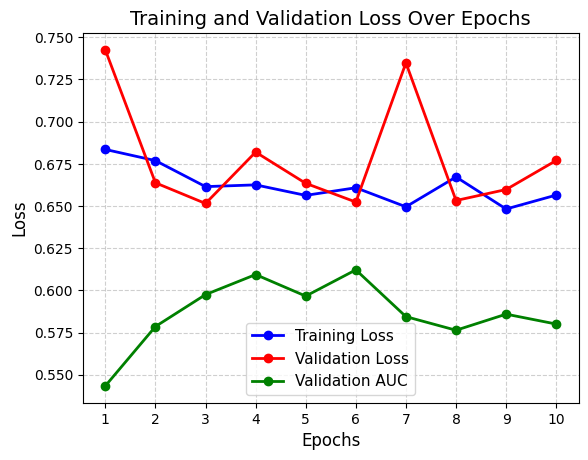

Plot successfully saved to /kaggle/working/loss_trend_fold_0.png
Training Complete for Fold 0. Best Validation AUC: 0.6122

--- Starting Training for Fold 1 on device: cuda ---


Epoch 1/20 [Valid]: 100%|██████████| 30/30 [00:59<00:00,  1.97s/it]



Epoch 1 Summary: Train Loss = 0.6919 | Valid Loss = 0.7673 | Valid AUC = 0.5509 | LR:0.00005000

Validation AUC improved from 0.0000 to 0.5509. Saving best_3d_model_fold_1.pth...



Epoch 2/20 [Valid]: 100%|██████████| 30/30 [00:58<00:00,  1.95s/it]



Epoch 2 Summary: Train Loss = 0.6799 | Valid Loss = 0.7192 | Valid AUC = 0.4464 | LR:0.00004970



Epoch 3/20 [Valid]: 100%|██████████| 30/30 [00:58<00:00,  1.93s/it]



Epoch 3 Summary: Train Loss = 0.6570 | Valid Loss = 0.7650 | Valid AUC = 0.4874 | LR:0.00004880



Epoch 4/20 [Valid]: 100%|██████████| 30/30 [00:59<00:00,  1.98s/it]



Epoch 4 Summary: Train Loss = 0.6509 | Valid Loss = 0.7824 | Valid AUC = 0.4946 | LR:0.00004733



Epoch 5/20 [Valid]: 100%|██████████| 30/30 [01:02<00:00,  2.08s/it]



Epoch 5 Summary: Train Loss = 0.6725 | Valid Loss = 0.6839 | Valid AUC = 0.4940 | LR:0.00004532

Early stopping triggered.


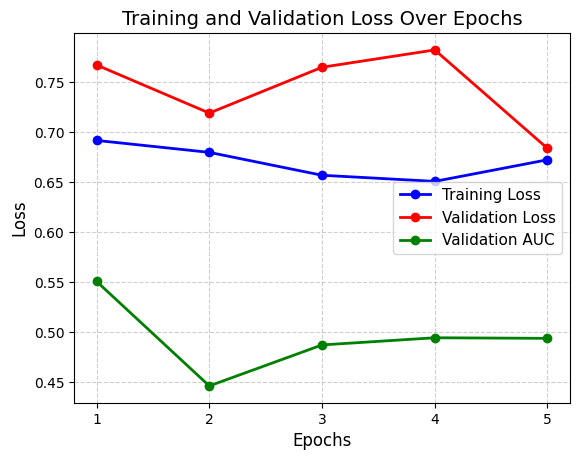

Plot successfully saved to /kaggle/working/loss_trend_fold_1.png
Training Complete for Fold 1. Best Validation AUC: 0.5509

--- Starting Training for Fold 2 on device: cuda ---


Epoch 1/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.98s/it]



Epoch 1 Summary: Train Loss = 0.6894 | Valid Loss = 0.6645 | Valid AUC = 0.6165 | LR:0.00005000

Validation AUC improved from 0.0000 to 0.6165. Saving best_3d_model_fold_2.pth...



Epoch 2/20 [Valid]: 100%|██████████| 29/29 [00:58<00:00,  2.03s/it]



Epoch 2 Summary: Train Loss = 0.6759 | Valid Loss = 0.7294 | Valid AUC = 0.4805 | LR:0.00004970



Epoch 3/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.98s/it]



Epoch 3 Summary: Train Loss = 0.6701 | Valid Loss = 0.7591 | Valid AUC = 0.4474 | LR:0.00004880



Epoch 4/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.99s/it]



Epoch 4 Summary: Train Loss = 0.6817 | Valid Loss = 0.6773 | Valid AUC = 0.4048 | LR:0.00004733



Epoch 5/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.97s/it]



Epoch 5 Summary: Train Loss = 0.6546 | Valid Loss = 0.6303 | Valid AUC = 0.6086 | LR:0.00004532

Early stopping triggered.


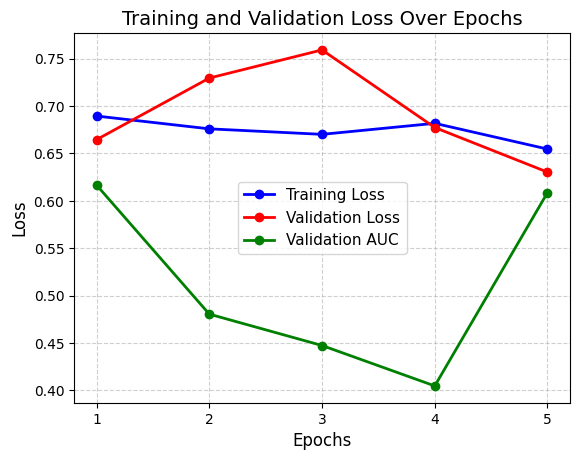

Plot successfully saved to /kaggle/working/loss_trend_fold_2.png
Training Complete for Fold 2. Best Validation AUC: 0.6165

--- Starting Training for Fold 3 on device: cuda ---


Epoch 1/20 [Valid]: 100%|██████████| 29/29 [00:58<00:00,  2.00s/it]



Epoch 1 Summary: Train Loss = 0.6888 | Valid Loss = 0.6520 | Valid AUC = 0.5908 | LR:0.00005000

Validation AUC improved from 0.0000 to 0.5908. Saving best_3d_model_fold_3.pth...



Epoch 2/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  2.00s/it]



Epoch 2 Summary: Train Loss = 0.6714 | Valid Loss = 0.6621 | Valid AUC = 0.5745 | LR:0.00004970



Epoch 3/20 [Valid]: 100%|██████████| 29/29 [00:58<00:00,  2.02s/it]



Epoch 3 Summary: Train Loss = 0.6627 | Valid Loss = 0.7231 | Valid AUC = 0.5063 | LR:0.00004880



Epoch 4/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.98s/it]



Epoch 4 Summary: Train Loss = 0.6611 | Valid Loss = 0.6723 | Valid AUC = 0.5425 | LR:0.00004733



Epoch 5/20 [Valid]: 100%|██████████| 29/29 [00:56<00:00,  1.96s/it]



Epoch 5 Summary: Train Loss = 0.6502 | Valid Loss = 0.7031 | Valid AUC = 0.5027 | LR:0.00004532

Early stopping triggered.


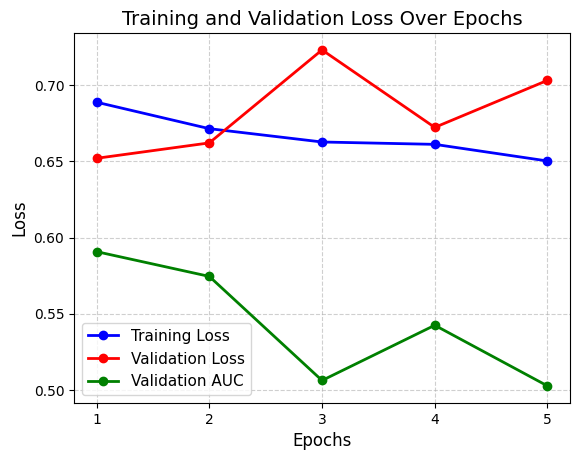

Plot successfully saved to /kaggle/working/loss_trend_fold_3.png
Training Complete for Fold 3. Best Validation AUC: 0.5908

--- Starting Training for Fold 4 on device: cuda ---


Epoch 1/20 [Valid]: 100%|██████████| 29/29 [00:56<00:00,  1.96s/it]



Epoch 1 Summary: Train Loss = 0.6814 | Valid Loss = 0.7196 | Valid AUC = 0.5253 | LR:0.00005000

Validation AUC improved from 0.0000 to 0.5253. Saving best_3d_model_fold_4.pth...



Epoch 2/20 [Valid]: 100%|██████████| 29/29 [00:57<00:00,  1.99s/it]



Epoch 2 Summary: Train Loss = 0.6664 | Valid Loss = 0.7398 | Valid AUC = 0.5434 | LR:0.00004970

Validation AUC improved from 0.5253 to 0.5434. Saving best_3d_model_fold_4.pth...



Epoch 3/20 [Valid]: 100%|██████████| 29/29 [00:58<00:00,  2.03s/it]


... (3 outputs left out)

Epoch 5/20 [Valid]: 100%|██████████| 29/29 [00:56<00:00,  1.95s/it]



Epoch 5 Summary: Train Loss = 0.6494 | Valid Loss = 0.7510 | Valid AUC = 0.4940 | LR:0.00004532



Epoch 6/20 [Valid]: 100%|██████████| 29/29 [00:56<00:00,  1.96s/it]



Epoch 6 Summary: Train Loss = 0.6478 | Valid Loss = 0.7300 | Valid AUC = 0.4423 | LR:0.00004282

Early stopping triggered.


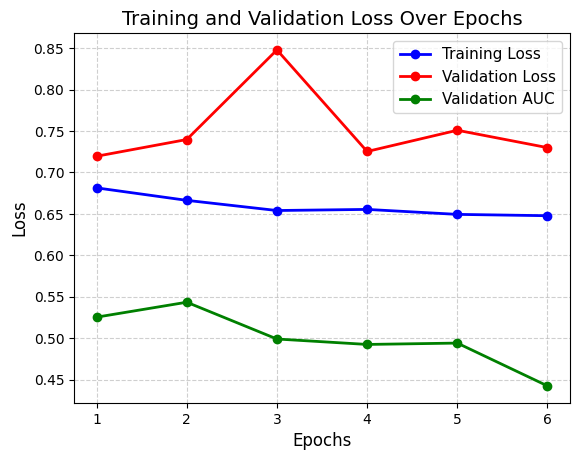

Plot successfully saved to /kaggle/working/loss_trend_fold_4.png
Training Complete for Fold 4. Best Validation AUC: 0.5434

--- Starting 5-Fold Ensemble Test Inference ---


[Test Inference]: 100%|██████████| 11/11 [01:20<00:00,  7.34s/it]

Inference Complete! Saved ensemble predictions to submission.csv


In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from torch.cuda.amp import GradScaler
from tqdm import tqdm
from typing import Optional

# (Assuming Dataset, Model_3D, mt, plot_loss, train_transform_func, val_transform_func are defined above)

class Trainer():
    def __init__(self, 
                 train_df: pd.DataFrame, 
                 val_df: pd.DataFrame,
                 fold_num: int,
                 epochs: int, 
                 device: str, 
                 train_transform_func, # type: mt.Compose
                 val_transform_func,   # type: mt.Compose
                 scaler: Optional[torch.cuda.amp.GradScaler]=None):
        """
        Args:
            train_df: Training fold dataframe
            val_df: Validation fold dataframe
            fold_num: Current fold index (used for saving distinct model weights)
            epochs: Number of epochs
            device: cpu / gpu 
            scaler: Optional GradScaler for mixed precision.
        """
        self.train_transform = train_transform_func
        self.val_transform = val_transform_func
        self.model = Model_3D(bb='resnet18')
        self.model.to(device)
        self.epochs = epochs
        self.optimizer = optim.AdamW(self.model.parameters(), lr=5e-5, weight_decay=1e-2)
        self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.optimizer, T_max=epochs, eta_min=1e-6)
        self.device = device
        self.scaler = scaler
        self.accumulation_steps = 4 
        self.fold_num = fold_num
        self.model_save_path = f'best_3d_model_fold_{fold_num}.pth'
        
        # ------------------- Loss & Eval ------------------
        pos_weights = (train_df['MGMT_value'] == 0).sum() / (train_df['MGMT_value'] == 1).sum()  
        pos_weight_tensor = torch.tensor([pos_weights], dtype=torch.float32).to(device)
        self.criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
        self.best_auc = 0.0
        
        # ------------------- Data Loader------------------
        train = train_df.reset_index(drop=True)
        val = val_df.reset_index(drop=True)
        
        train_ds = Dataset(train, scan_ids=train['BraTS21ID'], split='train', augmentation=self.train_transform)
        val_ds = Dataset(val, scan_ids=val['BraTS21ID'], split='train', augmentation=self.val_transform)

        self.train_loader = DataLoader(dataset=train_ds, batch_size=2, shuffle=True,
                                       num_workers=4, pin_memory=True) 
        
        self.valid_loader = DataLoader(dataset=val_ds, batch_size=4, shuffle=False,
                                       num_workers=4, pin_memory=True) 

    def train_one_epoch(self, epoch):
        self.model.train()
        running_loss = 0.0
        progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.epochs} [Train]")

        for inputs, targets in progress_bar:
            inputs = inputs.to(self.device, dtype=torch.float32)
            targets = targets.to(self.device, dtype=torch.float32)
            self.optimizer.zero_grad()

            if self.scaler is not None:
                with torch.cuda.amp.autocast():
                    outputs = self.model(inputs).squeeze(-1) 
                    loss = self.criterion(outputs, targets)
                self.scaler.scale(loss).backward()
                self.scaler.step(self.optimizer)
                self.scaler.update()
            else:
                outputs = self.model(inputs).squeeze(-1)
                loss = self.criterion(outputs, targets)
                loss.backward()
                self.optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

        return running_loss / len(self.train_loader.dataset)

    def train_one_epoch_accumulation(self, epoch):
        self.model.train()
        running_loss = 0.0
        progress_bar = tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.epochs} [Train]")
        self.optimizer.zero_grad()

        for i, (inputs, targets) in enumerate(progress_bar):
            inputs = inputs.to(self.device, dtype=torch.float32)
            targets = targets.to(self.device, dtype=torch.float32)

            if self.scaler is not None:
                with torch.cuda.amp.autocast():
                    outputs = self.model(inputs).squeeze(-1) 
                    loss = self.criterion(outputs, targets)
                    loss = loss / self.accumulation_steps
                self.scaler.scale(loss).backward()
            else:
                outputs = self.model(inputs).squeeze(-1)
                loss = self.criterion(outputs, targets)
                loss = loss / self.accumulation_steps
                loss.backward()

            if (i + 1) % self.accumulation_steps == 0 or (i + 1) == len(self.train_loader):
                if self.scaler is not None:
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                else:
                    self.optimizer.step()
                self.optimizer.zero_grad()
            
            running_loss += loss.item() * self.accumulation_steps * inputs.size(0)
            progress_bar.set_postfix({'loss': f"{loss.item() * self.accumulation_steps:.4f}"})

        return running_loss / len(self.train_loader.dataset)
    
    def valid_one_epoch(self, epoch):
        self.model.eval()
        running_loss = 0.0
        all_preds, all_targets = [], []
        progress_bar = tqdm(self.valid_loader, desc=f"Epoch {epoch}/{self.epochs} [Valid]")

        with torch.no_grad():
            for inputs, targets in progress_bar:
                inputs = inputs.to(self.device, dtype=torch.float32)
                targets = targets.to(self.device, dtype=torch.float32)

                if self.scaler is not None:
                    with torch.cuda.amp.autocast():
                        outputs = self.model(inputs).squeeze(-1)
                        loss = self.criterion(outputs, targets)
                else:
                    outputs = self.model(inputs).squeeze(-1)
                    loss = self.criterion(outputs, targets)

                running_loss += loss.item() * inputs.size(0)
                preds = torch.sigmoid(outputs).cpu().numpy()
                all_preds.extend(preds)
                all_targets.extend(targets.cpu().numpy())

        epoch_loss = running_loss / len(self.valid_loader.dataset)
        try:
            epoch_auc = roc_auc_score(all_targets, all_preds)
        except ValueError:
            print('batch only contains a single class')
            epoch_auc = 0.5 

        return epoch_loss, epoch_auc

    def training(self):
        print(f"\n--- Starting Training for Fold {self.fold_num} on device: {self.device} ---")
        patience = 0
        train_loss, valid_loss, valid_auc = [], [], []
        
        for epoch in range(1, self.epochs + 1):
            tr_loss = self.train_one_epoch_accumulation(epoch)
            val_loss, val_auc = self.valid_one_epoch(epoch)
            
            train_loss.append(tr_loss)
            valid_loss.append(val_loss)
            valid_auc.append(val_auc)
            
            print(f"\nEpoch {epoch} Summary: Train Loss = {tr_loss:.4f} | Valid Loss = {val_loss:.4f} | Valid AUC = {val_auc:.4f} | LR:{self.optimizer.param_groups[0]['lr']:.8f}\n")
            self.scheduler.step()
            
            if val_auc > self.best_auc:
                print(f"Validation AUC improved from {self.best_auc:.4f} to {val_auc:.4f}. Saving {self.model_save_path}...\n")
                self.best_auc = val_auc
                torch.save(self.model.state_dict(), self.model_save_path)
                patience = 0
            else:
                patience += 1 
                
            if patience == 4:
                print("Early stopping triggered.")
                break
                
        plot_loss(valid_loss, train_loss, valid_auc, f'loss_trend_fold_{self.fold_num}.png')     
        print(f"Training Complete for Fold {self.fold_num}. Best Validation AUC: {self.best_auc:.4f}")


def submit_ensemble(model_paths, device, val_transform_func, use_amp=True):
    """Loads all fold models, averages their predictions on the test set, and saves submission.csv"""
    print("\n--- Starting 5-Fold Ensemble Test Inference ---")
    test_df = pd.read_csv('/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/sample_submission.csv')
    test_df['BraTS21ID'] = test_df['BraTS21ID'].map('{:05}'.format)
    
    test_ds = Dataset(test_df, scan_ids=test_df['BraTS21ID'], split='test', augmentation=val_transform_func)
    test_loader = DataLoader(dataset=test_ds, batch_size=8, shuffle=False, num_workers=4, pin_memory=True) 
    
    # Load all 5 models into memory
    models = []
    for path in model_paths:
        model = Model_3D(bb='resnet18')
        model.load_state_dict(torch.load(path, map_location=device))
        model.to(device)
        model.eval()
        models.append(model)
    
    all_preds = []
    progress_bar = tqdm(test_loader, desc="[Test Inference]")
    
    with torch.no_grad():
        for batch in progress_bar:
            inputs = batch[0] if isinstance(batch, (list, tuple)) else batch
            inputs = inputs.to(device, dtype=torch.float32)
    
            batch_preds = []
            for model in models:
                if use_amp:
                    with torch.cuda.amp.autocast():
                        outputs = model(inputs).squeeze(-1)
                else:
                    outputs = model(inputs).squeeze(-1)
                
                preds = torch.sigmoid(outputs).cpu().numpy()
                batch_preds.append(preds)
                
            # Average predictions across all 5 models for this batch
            avg_preds = np.mean(batch_preds, axis=0)
            all_preds.extend(avg_preds)
    
    test_df['MGMT_value'] = all_preds
    test_df[['BraTS21ID', 'MGMT_value']].to_csv('submission.csv', index=False)
    print("Inference Complete! Saved ensemble predictions to submission.csv")   


# ==========================================
# Main Execution / 5-Fold Cross Validation
# ==========================================
if __name__ == '__main__':
    train_df = pd.read_csv(cfg.paths.train_root)
    train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
    values_to_drop = ['00109', '00123', '00709']
    df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)].reset_index(drop=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    model_paths = []

    # Iterate through the 5 folds
    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['MGMT_value'])):
        train_fold = df.iloc[train_idx]
        val_fold = df.iloc[val_idx]
        
        trainer = Trainer(
            train_df=train_fold,
            val_df=val_fold,
            fold_num=fold,
            epochs=20, 
            device=device, 
            train_transform_func=train_transform_func, # assumed defined globally
            val_transform_func=val_transform_func,     # assumed defined globally
            scaler=GradScaler()
        )
        
        trainer.training()
        model_paths.append(trainer.model_save_path)

    # After all 5 folds finish, evaluate the ensemble on the test set
    submit_ensemble(model_paths, device, val_transform_func, use_amp=True)

# Base Model

In [16]:
test_df = pd.read_csv('/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/sample_submission.csv')
# SCORE = 0.5

In [17]:

test_df['MGMT_value'] = np.random.rand(len(test_df))
#SCORE = 0.49

In [18]:
test_df['MGMT_value'] = 1
# SCORE = 0.5